In [1]:
import torch
print("GPU var mı:", torch.cuda.is_available())

!pip install -q kaggle
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000
!unzip -q skin-cancer-mnist-ham10000.zip -d ham10000

GPU var mı: True
Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:36<00:00, 152MB/s]



In [2]:
import os, glob, numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score

DATA_DIR = "ham10000"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
meta = pd.read_csv(os.path.join(DATA_DIR, "HAM10000_metadata.csv"))
meta["label"] = meta["dx"].apply(lambda d: 1 if d in {"mel", "bcc", "akiec"} else 0)
paths = {os.path.splitext(os.path.basename(p))[0]: p
         for p in glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True)}
meta["path"] = meta["image_id"].map(paths)
meta = meta.dropna(subset=["path"])

gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, temp_idx = next(gss.split(meta, groups=meta["lesion_id"]))
temp_df = meta.iloc[temp_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df["lesion_id"]))
val_df, test_df = temp_df.iloc[val_idx], temp_df.iloc[test_idx]

eval_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

class LesionDS(Dataset):
    def __init__(self, df): self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return eval_tf(Image.open(r["path"]).convert("RGB")), int(r["label"])

model = models.mobilenet_v2(weights=None)
model.classifier[1] = nn.Linear(model.last_channel, 2)
model.load_state_dict(torch.load("en_iyi_model.pt", map_location=DEVICE))
model = model.to(DEVICE).eval()

def tahmin(df):
    probs = []
    with torch.no_grad():
        for x, _ in DataLoader(LesionDS(df), batch_size=64, num_workers=2):
            probs += torch.softmax(model(x.to(DEVICE)), 1)[:, 1].cpu().tolist()
    out = df[["image_id", "lesion_id", "dx", "label", "path"]].copy()
    out["prob"] = probs
    return out

val_p, test_p = tahmin(val_df), tahmin(test_df)
val_p.to_csv("val_tahmin.csv", index=False)
test_p.to_csv("test_tahmin.csv", index=False)
print("Doğrulama AUC:", round(roc_auc_score(val_p.label, val_p.prob), 4))
print("Test AUC:", round(roc_auc_score(test_p.label, test_p.prob), 4))

Doğrulama AUC: 0.9126
Test AUC: 0.9181


 eşik  duyarlılık  kesinlik  yanlış alarm  kaçırılan
 0.20       0.928     0.439           330         20
 0.25       0.910     0.460           297         25
 0.30       0.896     0.477           273         29
 0.35       0.867     0.488           253         37
 0.40       0.842     0.506           228         44
 0.45       0.820     0.518           212         50
 0.50       0.799     0.531           196         56
 0.55       0.763     0.559           167         66
 0.60       0.745     0.575           153         71
 0.65       0.716     0.612           126         79
 0.70       0.658     0.638           104         95

Seçilen eşik: 0.35


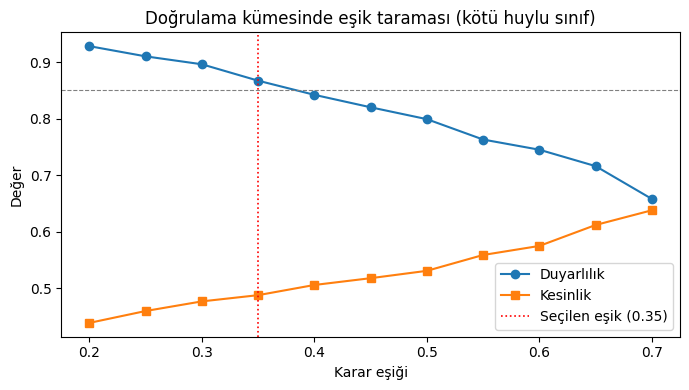

In [3]:
import matplotlib.pyplot as plt
from sklearn.metrics import recall_score, precision_score

esikler = np.round(np.arange(0.20, 0.71, 0.05), 2)
satirlar = []
for t in esikler:
    pred = (val_p.prob >= t).astype(int)
    satirlar.append({"eşik": t,
                     "duyarlılık": recall_score(val_p.label, pred),
                     "kesinlik": precision_score(val_p.label, pred),
                     "yanlış alarm": int(((pred == 1) & (val_p.label == 0)).sum()),
                     "kaçırılan": int(((pred == 0) & (val_p.label == 1)).sum())})
tablo = pd.DataFrame(satirlar).round(3)
print(tablo.to_string(index=False))
tablo.to_csv("esik_taramasi.csv", index=False)

uygun = tablo[tablo["duyarlılık"] >= 0.85]
secilen = float(uygun["eşik"].max()) if len(uygun) else float(tablo["eşik"].min())
print("\nSeçilen eşik:", secilen)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tablo["eşik"], tablo["duyarlılık"], "o-", label="Duyarlılık")
ax.plot(tablo["eşik"], tablo["kesinlik"], "s-", label="Kesinlik")
ax.axhline(0.85, ls="--", color="gray", lw=0.8)
ax.axvline(secilen, ls=":", color="red", lw=1.2, label=f"Seçilen eşik ({secilen})")
ax.set_xlabel("Karar eşiği"); ax.set_ylabel("Değer")
ax.set_title("Doğrulama kümesinde eşik taraması (kötü huylu sınıf)")
ax.legend(); plt.tight_layout(); plt.savefig("esik_taramasi.png", dpi=150); plt.show()

Eşik = 0.35
              precision    recall  f1-score   support

   İyi huylu       0.95      0.82      0.88      1176
  Kötü huylu       0.56      0.83      0.67       318

    accuracy                           0.82      1494
   macro avg       0.75      0.83      0.77      1494
weighted avg       0.86      0.82      0.84      1494

Karmaşıklık matrisi:
 [[968 208]
 [ 54 264]]


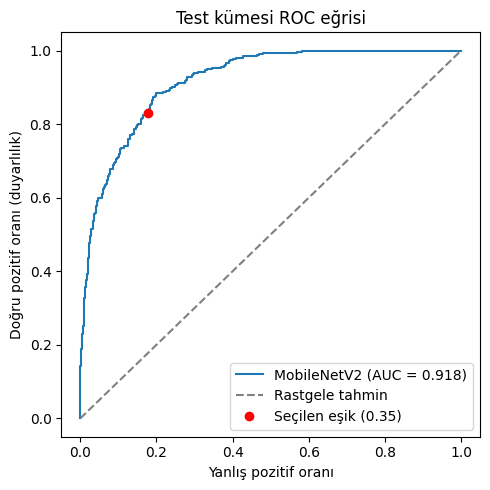

In [4]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

pred_test = (test_p.prob >= secilen).astype(int)
print(f"Eşik = {secilen}")
print(classification_report(test_p.label, pred_test, target_names=["İyi huylu", "Kötü huylu"]))
cm = confusion_matrix(test_p.label, pred_test)
print("Karmaşıklık matrisi:\n", cm)

tn, fp, fn, tp = cm.ravel()
fpr, tpr, _ = roc_curve(test_p.label, test_p.prob)
auc = roc_auc_score(test_p.label, test_p.prob)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label=f"MobileNetV2 (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Rastgele tahmin")
ax.plot(fp / (fp + tn), tp / (tp + fn), "ro", label=f"Seçilen eşik ({secilen})")
ax.set_xlabel("Yanlış pozitif oranı"); ax.set_ylabel("Doğru pozitif oranı (duyarlılık)")
ax.set_title("Test kümesi ROC eğrisi"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("roc_test.png", dpi=150); plt.show()

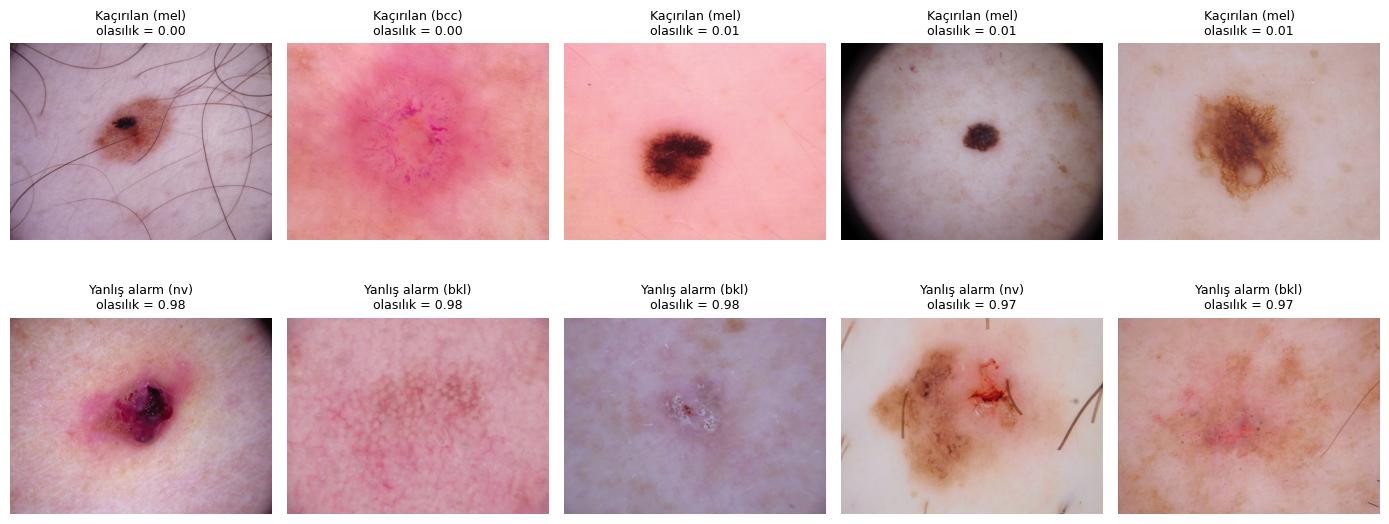

In [5]:
sonuc = test_p.assign(pred=pred_test)
kacan = sonuc[(sonuc.label == 1) & (sonuc.pred == 0)].nsmallest(5, "prob")
alarm = sonuc[(sonuc.label == 0) & (sonuc.pred == 1)].nlargest(5, "prob")

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, (_, r) in zip(axes[0], kacan.iterrows()):
    ax.imshow(Image.open(r.path)); ax.axis("off")
    ax.set_title(f"Kaçırılan ({r.dx})\nolasılık = {r.prob:.2f}", fontsize=9)
for ax, (_, r) in zip(axes[1], alarm.iterrows()):
    ax.imshow(Image.open(r.path)); ax.axis("off")
    ax.set_title(f"Yanlış alarm ({r.dx})\nolasılık = {r.prob:.2f}", fontsize=9)
plt.tight_layout(); plt.savefig("hatali_tahminler.png", dpi=120); plt.show()